# 03 · Exploratory analysis, statistical tests and charts

**Research question:** do companies with lower ESG risk perform better in the stock market, in terms of returns, risk and behaviour during crises?

**Input:** `data/analysis_dataset.csv`
**Outputs:** `data/analysis_final.csv`, charts in `figures/`

## 1. Load the data and order ESG risk levels
Levels are ordered from best to worst so that tables and charts follow that order. Remember: **lower ESG risk = more sustainable company**.

In [1]:
import pandas as pd

df = pd.read_csv("../data/analysis_dataset.csv")

# Order ESG risk levels from best to worst
order = ["Negligible", "Low", "Medium", "High", "Severe"]
df["esg_level"] = pd.Categorical(df["esg_level"], categories=order, ordered=True)

df["esg_level"].value_counts().sort_index()

esg_level
Negligible      5
Low           179
Medium        177
High           47
Severe          3
Name: count, dtype: int64

## 2. ESG risk by sector

In [2]:
df.groupby("sector")["esg_total"].agg(["mean", "count"]).sort_values("mean").round(1)

,mean,count
sector,,
Real Estate,13.3,26
Technology,16.7,57
Consumer Cyclical,19.2,51
Healthcare,20.6,51
Financial Services,21.1,59
Communication Services,21.2,11
Industrials,24.0,60
Consumer Defensive,25.4,32
Utilities,26.7,28


ESG risk depends heavily on the sector: Energy has the highest average risk (31.8) and Real Estate the lowest (13.3).

## 3. Raw comparison by ESG risk level
Medians are used instead of means so that extreme values do not distort the results.

In [3]:
metrics = ["annual_return", "volatility", "max_drawdown", "covid_crash", "return_2022"]
df.groupby("esg_level", observed=True)[metrics].median().round(3)

,annual_return,volatility,max_drawdown,covid_crash,return_2022
esg_level,,,,,
Negligible,0.114,0.334,-0.460,-0.372,-0.291
Low,0.131,0.322,-0.484,-0.362,-0.182
Medium,0.113,0.300,-0.477,-0.375,-0.066
High,0.106,0.363,-0.561,-0.429,0.128
Severe,0.134,0.385,-0.603,-0.515,0.874


First reading of the raw results:
- **Annual return** is roughly flat across levels.
- **Risk** (volatility, max drawdown, COVID crash) is worse for High and Severe ESG risk.
- **2022:** the worse the ESG risk, the better the return (+87% for Severe). This is suspicious.

Two problems: the Negligible (5) and Severe (3) groups are too small, and the 2022 result may be a **sector effect**. Who are the Severe companies?

In [4]:
df[df["esg_level"] == "Severe"][["ticker", "company_name", "sector", "return_2022"]]

,ticker,company_name,sector,return_2022
139,OXY,Occidental Petroleum Corporation,Energy,1.190984
245,GE,General Electric Company,Industrials,-0.109232
264,XOM,Exxon Mobil Corporation,Energy,0.874091


Two of the three Severe companies are oil majors, which rose sharply in 2022 with oil prices. The raw result reflects the sector, not ESG.

## 4. Merge small groups into three ESG risk groups
Negligible + Low → **Low risk**; Medium → **Medium risk**; High + Severe → **High risk**. All groups now have enough companies to compare.

In [5]:
# Merge small groups into three ESG risk groups
group_map = {
    "Negligible": "Low risk", "Low": "Low risk",
    "Medium": "Medium risk",
    "High": "High risk", "Severe": "High risk"
}
df["esg_group"] = df["esg_level"].map(group_map)
df["esg_group"] = pd.Categorical(
    df["esg_group"], categories=["Low risk", "Medium risk", "High risk"], ordered=True
)

df["esg_group"].value_counts().sort_index()

esg_group
Low risk       184
Medium risk    177
High risk       50
Name: count, dtype: int64

## 5. Controlling for sector
To isolate the ESG effect, each metric is expressed **relative to the median of the company's sector**. An oil company is only compared with other oil companies, so any remaining gap between ESG groups cannot be explained by the sector.

In [6]:
# Each metric relative to the median of its sector
for m in metrics:
    df[f"{m}_vs_sector"] = df[m] - df.groupby("sector")[m].transform("median")

adj_metrics = [f"{m}_vs_sector" for m in metrics]
df.groupby("esg_group", observed=True)[adj_metrics].median().round(3)

,annual_return_vs_sector,volatility_vs_sector,max_drawdown_vs_sector,covid_crash_vs_sector,return_2022_vs_sector
esg_group,,,,,
Low risk,0.000,-0.001,0.005,0.011,-0.011
Medium risk,0.001,-0.001,0.000,-0.005,-0.011
High risk,-0.006,0.033,-0.042,-0.031,0.080


After the sector adjustment:
- **Returns:** practically no difference between groups.
- **Risk:** high ESG-risk companies are still more volatile and fall more than their sector peers.
- **2022:** the advantage of high ESG-risk companies shrinks from +87% to about +8 pp, but does not disappear.

## 6. Statistical tests
Are these differences real or due to chance?
- **Mann-Whitney U:** compares the high and low ESG-risk groups. Used instead of a t-test because stock returns are not normally distributed.
- **Spearman correlation (ρ):** relationship between the exact ESG score and each metric across all 411 companies.

A p-value below 0.05 is considered statistically significant.

In [8]:
from scipy import stats

low = df[df["esg_group"] == "Low risk"]
high = df[df["esg_group"] == "High risk"]

results = []
for m in adj_metrics:
    # Do high- and low-risk companies differ?
    _, p_groups = stats.mannwhitneyu(high[m], low[m])
    # Is the ESG score correlated with the metric across all companies?
    rho, p_corr = stats.spearmanr(df["esg_total"], df[m])
    results.append({
        "metric": m,
        "median_diff_high_vs_low": high[m].median() - low[m].median(),
        "p_value_groups": p_groups,
        "spearman_rho": rho,
        "p_value_corr": p_corr
    })

pd.DataFrame(results).round(3)

,metric,median_diff_high_vs_low,p_value_groups,spearman_rho,p_value_corr
0,annual_return_vs_sector,-0.006,0.917,-0.037,0.460
1,volatility_vs_sector,0.034,0.001,0.141,0.004
2,max_drawdown_vs_sector,-0.048,0.006,-0.108,0.029
3,covid_crash_vs_sector,-0.042,0.003,-0.163,0.001
4,return_2022_vs_sector,0.091,0.006,0.057,0.253


### Statistical results
- **Returns:** no significant relationship between ESG risk and annual returns once sector is controlled for (p = 0.92).
- **Risk:** high ESG-risk companies show significantly higher volatility (+3.4 pp), deeper maximum drawdowns (−4.8 pp) and larger losses during the COVID crash (−4.2 pp) than low-risk peers in the same sector (all p < 0.01).
- **Effect size:** correlations are weak (|ρ| ≈ 0.11–0.16), so ESG risk explains only a small part of a company's risk profile.
- **2022:** the group difference is significant (p = 0.006) but the correlation is not (p = 0.25): the effect is not gradual and is concentrated in the high-risk group.

## 7. Robustness check: excluding the energy sector
Energy has both the highest ESG risk and unusual returns. All tests are repeated without it.

In [9]:
# Robustness check: repeat the tests excluding the energy sector
df_ex = df[df["sector"] != "Energy"]
low_ex = df_ex[df_ex["esg_group"] == "Low risk"]
high_ex = df_ex[df_ex["esg_group"] == "High risk"]

results_ex = []
for m in adj_metrics:
    _, p_groups = stats.mannwhitneyu(high_ex[m], low_ex[m])
    results_ex.append({
        "metric": m,
        "median_diff_high_vs_low": high_ex[m].median() - low_ex[m].median(),
        "p_value_groups": p_groups
    })

pd.DataFrame(results_ex).round(3)

,metric,median_diff_high_vs_low,p_value_groups
0,annual_return_vs_sector,-0.006,0.954
1,volatility_vs_sector,0.038,0.000
2,max_drawdown_vs_sector,-0.080,0.002
3,covid_crash_vs_sector,-0.045,0.002
4,return_2022_vs_sector,0.090,0.019


### Robustness results
- The relationship between ESG risk and higher risk **holds, and becomes stronger**, when energy companies are excluded (max drawdown −8.0 pp, p = 0.002). The ESG–risk link is therefore not driven by oil companies.
- The 2022 outperformance of high ESG-risk companies **also persists** (+9.0 pp, p = 0.019), so it is not explained by energy alone. A possible explanation is the 2022 rotation from growth towards traditional, asset-heavy businesses, which tend to carry higher ESG risk. This hypothesis is not tested here and is left for further research.

## 8. Save the final dataset

In [10]:
df.to_csv("../data/analysis_final.csv", index=False)

## 9. Charts
Charts are saved in `figures/` for the README and the presentation. Colours are consistent across charts: green = low ESG risk, yellow = medium, red = high.

In [12]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter

# Folder to save charts for the README and presentation
os.makedirs("../figures", exist_ok=True)

sns.set_theme(style="whitegrid")
palette = {"Low risk": "#2a9d8f", "Medium risk": "#e9c46a", "High risk": "#e76f51"}

### Chart 1 · ESG risk by sector
Context: ESG risk depends heavily on the sector, which is why the analysis controls for it.

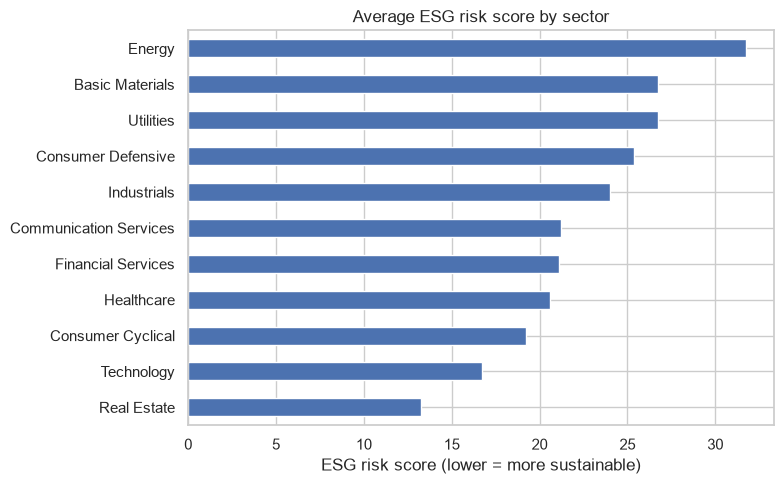

In [16]:
sector_esg = df.groupby("sector")["esg_total"].mean().sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
sector_esg.plot(kind="barh", ax=ax, color="#4C72B0")
ax.set_title("Average ESG risk score by sector")
ax.set_xlabel("ESG risk score (lower = more sustainable)")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig("../figures/esg_by_sector.png", dpi=150)
plt.show()

### Chart 2 · Risk by ESG group, relative to sector
The dashed line marks the sector median. The high-risk box sits **above** it for volatility and **below** it for max drawdown and the COVID crash. The boxes overlap considerably: the effect is real but modest.

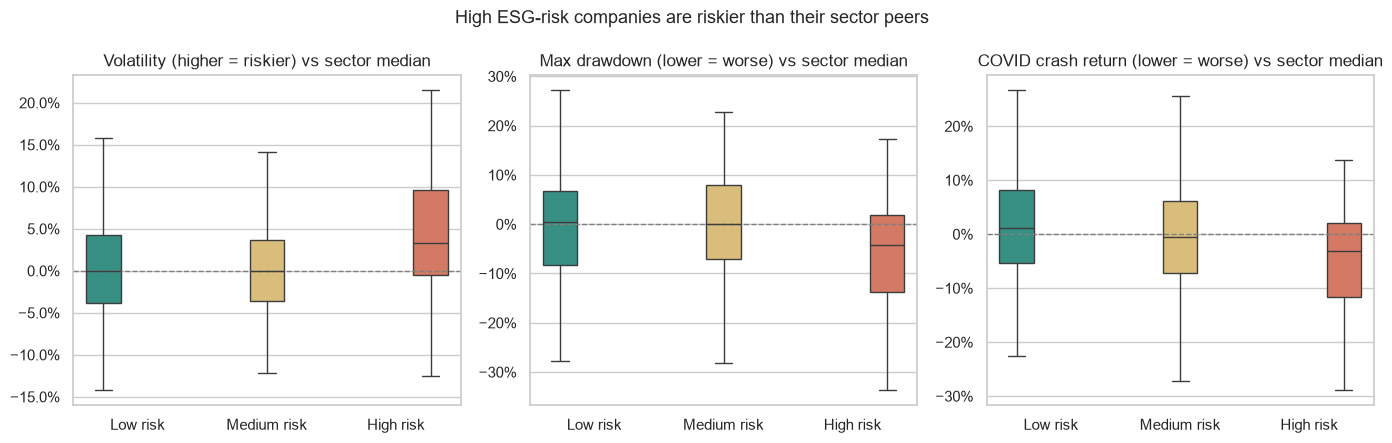

In [17]:
risk_cols = {
    "volatility_vs_sector": "Volatility (higher = riskier)",
    "max_drawdown_vs_sector": "Max drawdown (lower = worse)",
    "covid_crash_vs_sector": "COVID crash return (lower = worse)"
}

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, (col, title) in zip(axes, risk_cols.items()):
    sns.boxplot(data=df, x="esg_group", y=col, hue="esg_group",
                palette=palette, legend=False, showfliers=False, ax=ax)
    ax.axhline(0, color="grey", linestyle="--", linewidth=1)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.yaxis.set_major_formatter(PercentFormatter(1))

fig.suptitle("High ESG-risk companies are riskier than their sector peers", fontsize=13)
plt.tight_layout()
plt.savefig("../figures/risk_by_esg_group.png", dpi=150)
plt.show()

### Chart 3 · 2022 returns, raw vs sector-adjusted
The sector adjustment reduces the advantage of high ESG-risk companies, but does not remove it.

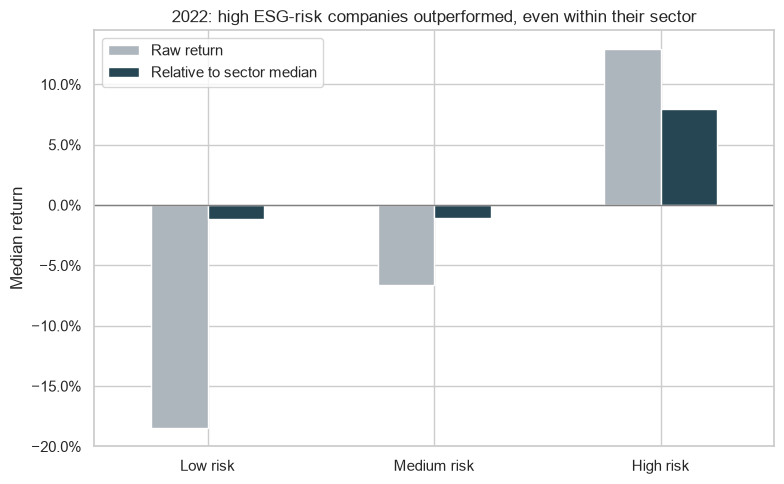

In [18]:
summary_2022 = df.groupby("esg_group", observed=True)[["return_2022", "return_2022_vs_sector"]].median()
summary_2022.columns = ["Raw return", "Relative to sector median"]

fig, ax = plt.subplots(figsize=(8, 5))
summary_2022.plot(kind="bar", ax=ax, color=["#adb5bd", "#264653"])
ax.axhline(0, color="grey", linewidth=1)
ax.set_title("2022: high ESG-risk companies outperformed, even within their sector")
ax.set_xlabel("")
ax.set_ylabel("Median return")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig("../figures/returns_2022.png", dpi=150)
plt.show()

## Conclusions
1. **ESG risk is not a return signal.** Within each sector, ESG risk did not explain long-term returns.
2. **ESG risk is a modest risk signal.** High ESG-risk companies were more volatile, had deeper drawdowns and fell more in the COVID crash than their sector peers. The effect is statistically significant but small.
3. **Sector comes first.** Without controlling for sector, the raw data suggests the opposite of what is true (e.g. +87% for Severe companies in 2022).

**ESG risk ratings behave like a risk indicator, not a source of extra return.**

## Limitations
- One 2023 rating snapshot applied to 2019–2025: ratings may have changed during the period.
- Survivorship bias: 18 companies without price data were removed.
- One rating provider (Sustainalytics); providers often disagree.
- No controls for size, value or market beta.
- Correlation, not causation.

## Next steps
- Use historical, point-in-time ESG ratings.
- Regression with Fama-French factors.
- Compare Sustainalytics with other providers (e.g. MSCI).
- Test the 2022 growth-to-value hypothesis.
- Extend the analysis to European markets (STOXX 600).